In [1]:
from include.envs import SimpleRoTDetector

env = SimpleRoTDetector(n_tracks=100, spatial_res=0.1, time_res=0.3, tof_margin=50.0)

In [2]:
from skrl.models.torch import Model, DeterministicMixin
from torch import nn
import torch


class Actor(DeterministicMixin, Model):
    def __init__(self, observation_space, action_space, device):
        Model.__init__(self, observation_space=observation_space, action_space=action_space, device=device)
        DeterministicMixin.__init__(self, clip_actions=True)

        self.net = nn.Sequential(
            nn.Linear(self.num_observations, 2**10), nn.ReLU(),
            nn.Linear(2**10, 2**12), nn.ReLU(),
            nn.Linear(2**12, 2**10), nn.ReLU(),
            nn.Linear(2**10, self.num_actions), nn.Tanh(),
        )

    def compute(self, inputs, role=""):
        return self.net(inputs["observations"]), {}


class Critic(DeterministicMixin, Model):
    def __init__(self, observation_space, action_space, device):
        Model.__init__(self, observation_space=observation_space, action_space=action_space, device=device)
        DeterministicMixin.__init__(self, clip_actions=False)

        self.net = nn.Sequential(
            nn.Linear(self.num_observations + self.num_actions, 2**12), nn.ReLU(),
            nn.Linear(2**12, 2**10), nn.ReLU(),
            nn.Linear(2**10, 2**8), nn.ReLU(),
            nn.Linear(2**8, 1),
        )

    def compute(self, inputs, role=""):
        x = torch.cat([inputs["observations"], inputs["taken_actions"]], dim=-1)
        return self.net(x), {}


In [3]:
from skrl.envs.wrappers.torch import wrap_env
from skrl.memories.torch import RandomMemory
from skrl.resources.noises.torch import GaussianNoise
from skrl.agents.torch.ddpg import DDPG, DDPG_CFG

device = "cuda" if torch.cuda.is_available() else "cpu"

env = wrap_env(env, wrapper = 'gymnasium')
memory = RandomMemory(memory_size=20000, num_envs=env.num_envs, device=device)

models = {
    "policy": Actor(env.observation_space, env.action_space, device),
    "target_policy": Actor(env.observation_space, env.action_space, device),
    "critic": Critic(env.observation_space, env.action_space, device),
    "target_critic": Critic(env.observation_space, env.action_space, device),
}

cfg = DDPG_CFG(
    batch_size=128,
    discount_factor=0,
    polyak=0.01,
    learning_rate=1e-4,
    random_timesteps=1000,
    learning_starts=2000,
    exploration_noise=GaussianNoise,
    exploration_noise_kwargs={"mean": 0.0, "std": 0.2, "device": device},
)
cfg.experiment.write_interval = 20
cfg.experiment.checkpoint_interval = 0
cfg.experiment.experiment_name = "ddpg_RoT-stable"
cfg.experiment.directory = "./runs"
cfg.close_environment_at_exit = True
cfg.timesteps = 50000
cfg.disable_progressbar = False
cfg.headless = True
cfg.environment_info = True

agent = DDPG(
    models=models,
    memory=memory,
    observation_space=env.observation_space,
    action_space=env.action_space,
    device=device,
    cfg=cfg,
)


[skrl:INFO] Environment wrapper: Gymnasium


[skrl:WARNING] Failed to check for a vectorized environment: module 'gymnasium.experimental' has no attribute 'vector'


  2%|▏         | 945/50000 [00:00<00:31, 1539.47it/s]

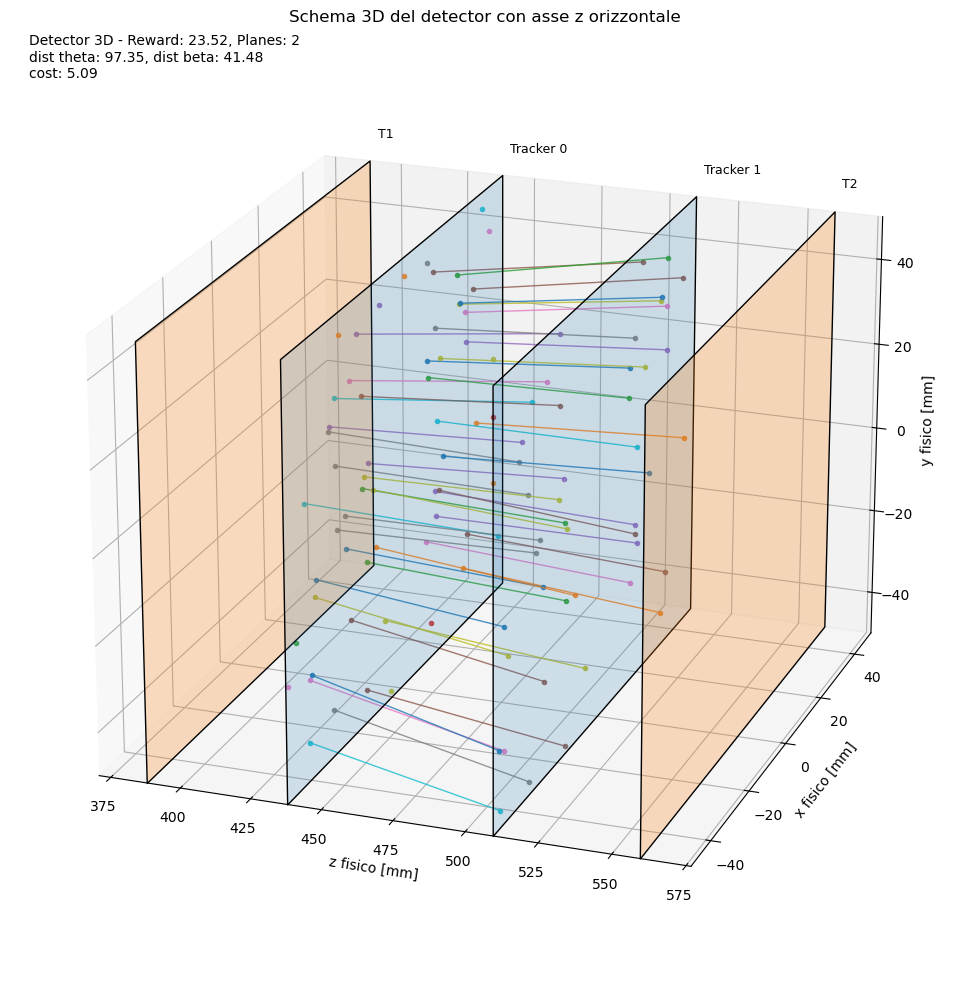

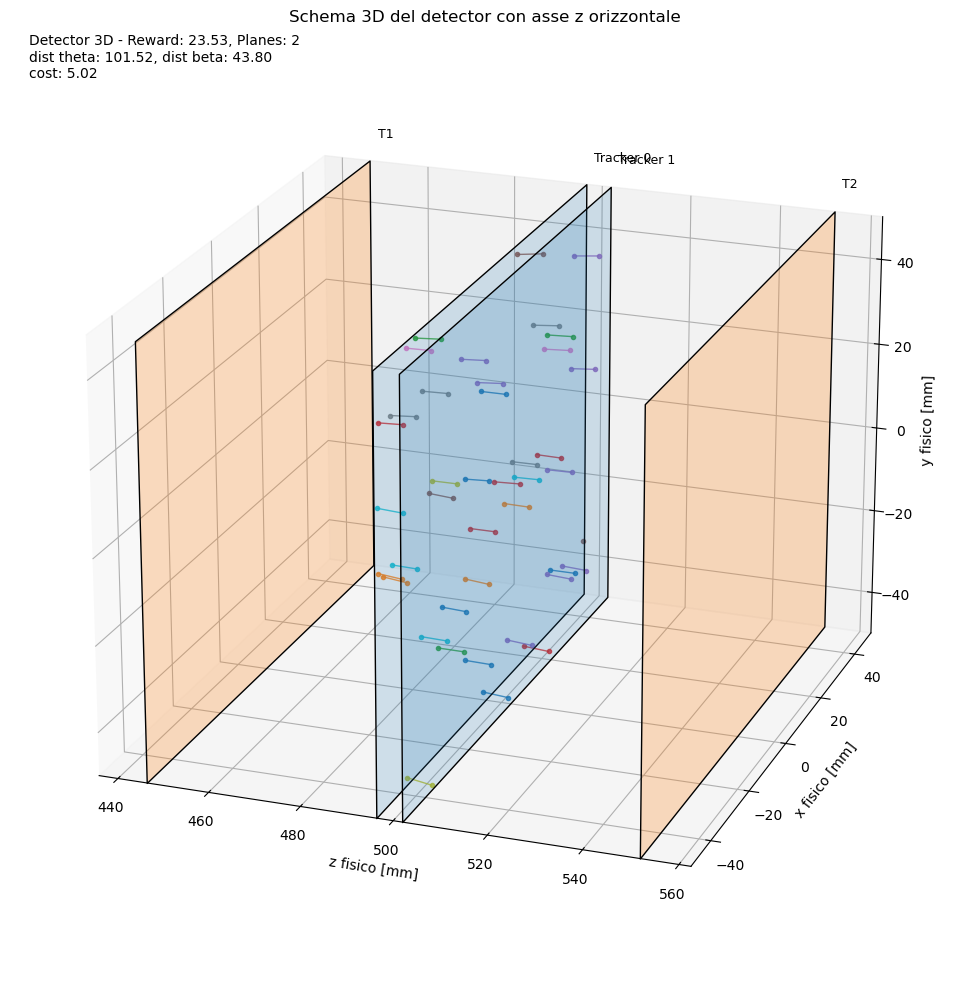

  2%|▏         | 1206/50000 [00:04<05:57, 136.30it/s]

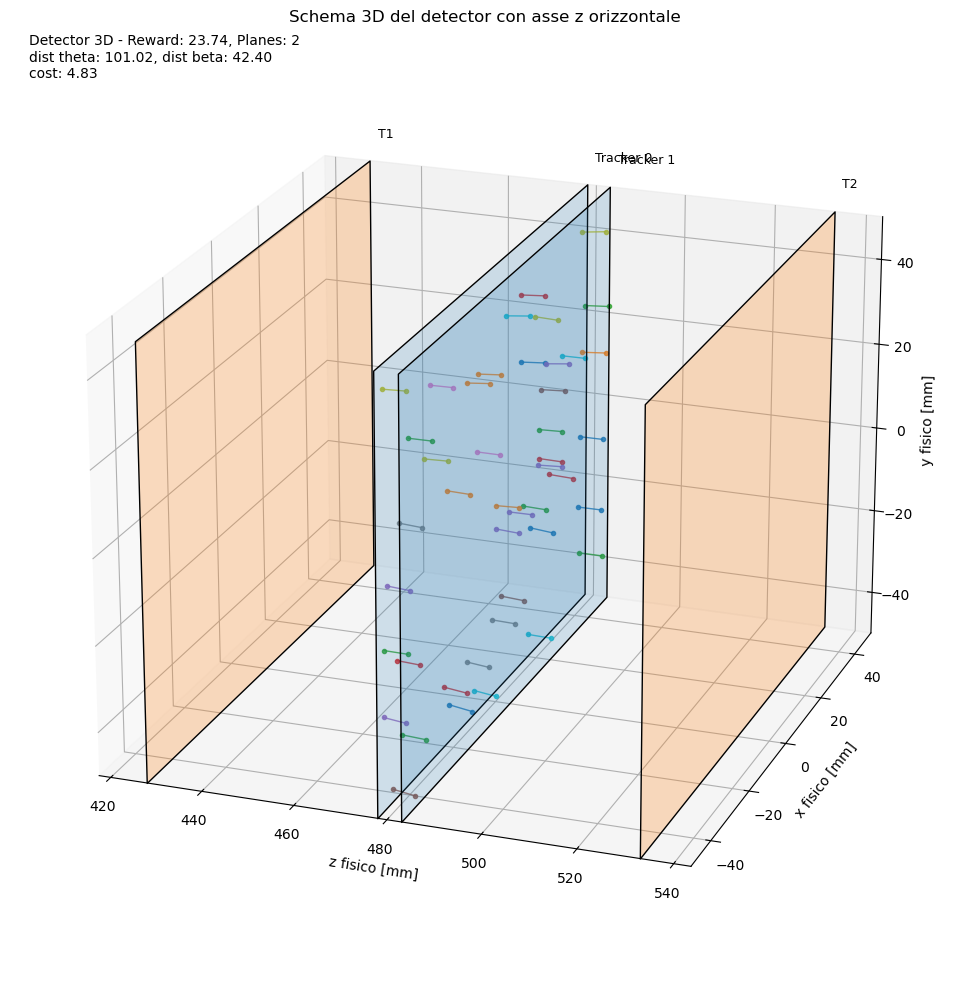

  3%|▎         | 1334/50000 [00:06<08:06, 99.99it/s] 

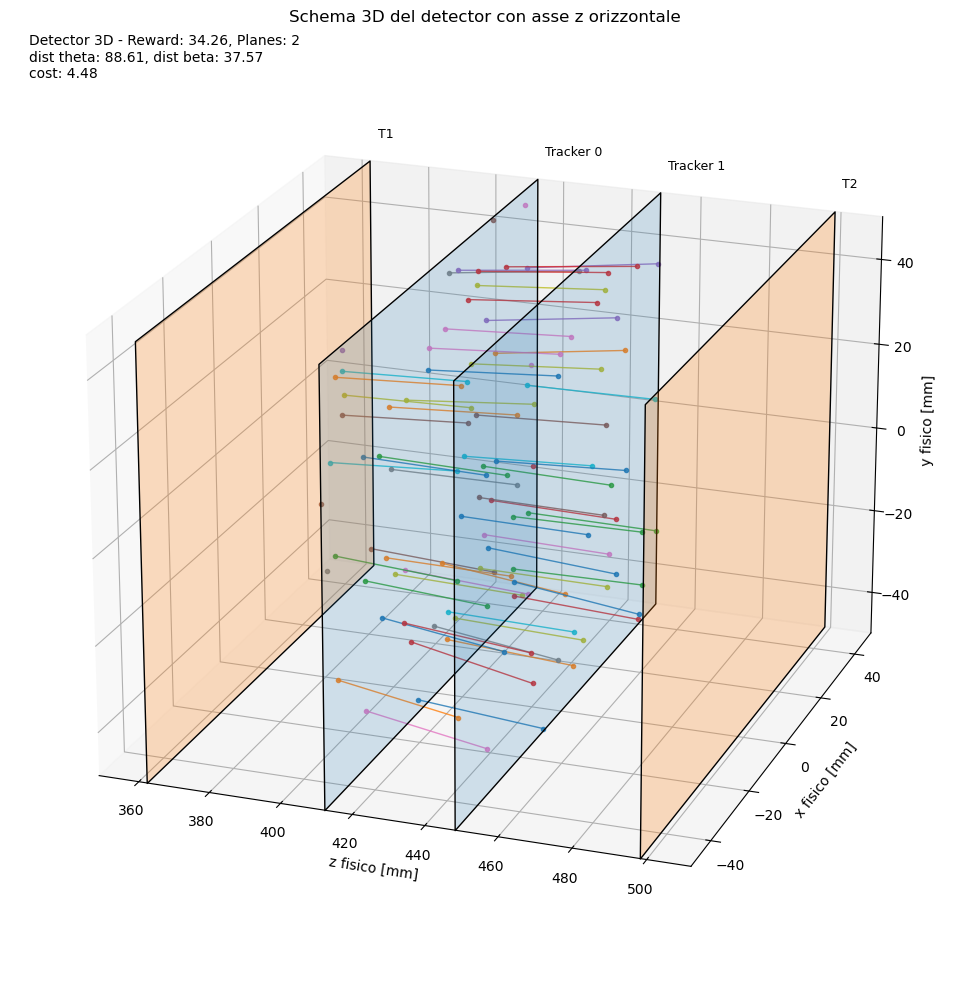

  4%|▎         | 1823/50000 [00:12<07:50, 102.41it/s]

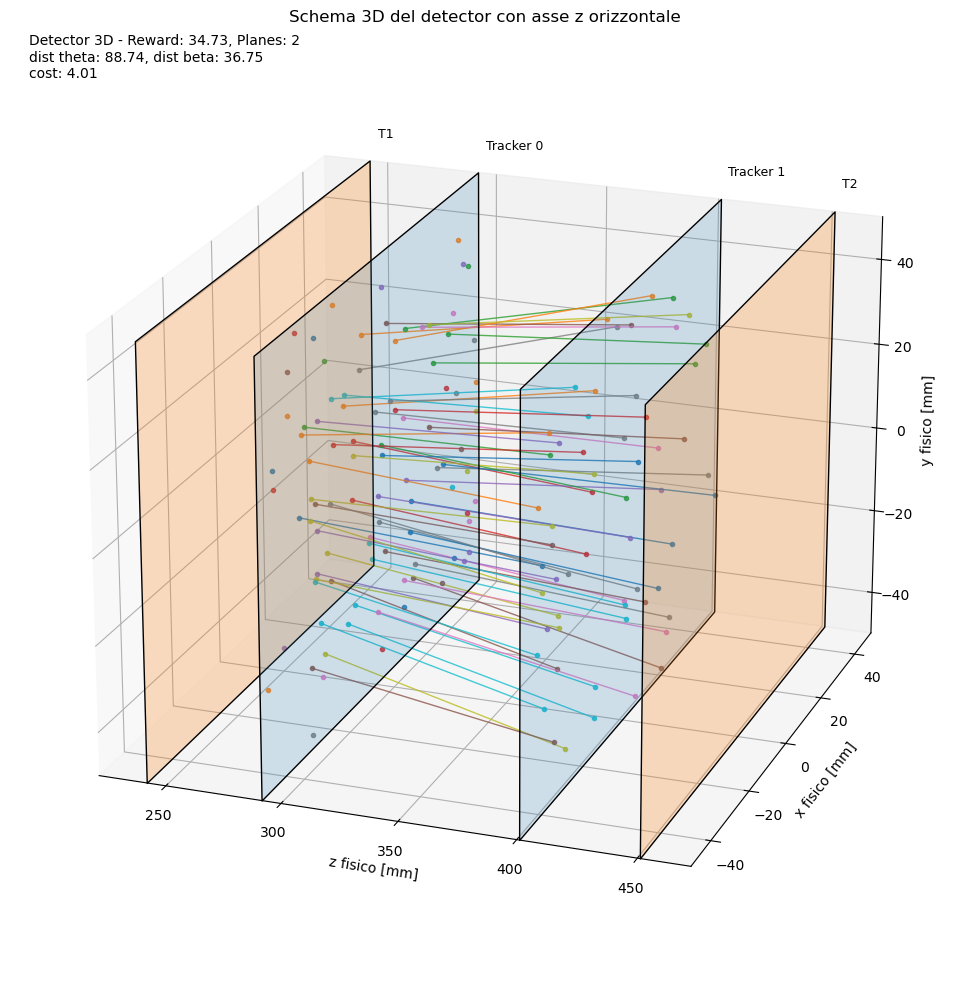

  4%|▍         | 1999/50000 [00:15<09:28, 84.38it/s] 

KeyboardInterrupt: 

  4%|▍         | 2004/50000 [00:30<09:28, 84.38it/s]

In [4]:
from include.misc import customTrainer

custom = customTrainer(env, agent, cfg, logdir='runs', health_logs=True)
custom.train()

In [ ]:
import time
from skrl.trainers.torch import SequentialTrainer, SequentialTrainerCfg
trainer = SequentialTrainer(env=env, agents=agent, cfg=cfg)
trainer.train()